# Experimental: 3-D wind projected onto a cross-section plane

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section 3D Parallel Wind](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_wind_3d.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. The horizontal part (the line, its tangent vectors and the regridding onto the line) uses the new `earthkit.geo.polyline` module, whose interface may still change. The computations on the model levels (the pressure on the hybrid levels, the vertical velocity in m/s and the interpolation to pressure levels) use `earthkit.meteo`.

The plot shows arrows in the vertical plane under a line from (48.32°N, 1.18°E) to (40.43°N, 2.44°E), which goes roughly southwards across the Pyrenees. The horizontal component of each arrow is the **wind component along the line**, in m/s: it is positive in the direction of travel, i.e. southwards. The vertical component is the **vertical velocity** `w` in m/s, positive upwards, multiplied by 50 so that it is visible (as in Metview). The arrows are at fixed pressure levels, from 1000 to 250 hPa every 25 hPa.

The notebook reads a GRIB file. It contains forecast data on 91 hybrid model levels for 2011-12-15 12 UTC, step 24 h. 

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import polyline_normals, sample_polyline
from earthkit.meteo import vertical, wind

## Load the data

The file contains the wind components `u` and `v`, the pressure velocity `w` (omega, in Pa/s) and the temperature `t` on the 91 hybrid model levels, and the logarithm of the surface pressure `lnsp`, which has a single field. It is a GRIB2 file on a regular 0.1° latitude-longitude grid over the area 40–48.5°N, 1–2.5°E. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "joachim_ml.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

joachim_ml.grib:   0%|          | 0.00/1.29M [00:00<?, ?B/s]

365 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,u,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
1,v,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
2,w,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
3,t,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
4,lnsp,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,1,hybrid,None,regular_ll
5,u,2011-12-16 12:00:00,2011-12-15 12:00:00,1 days,2,hybrid,None,regular_ll


## Select the fields

We select `u`, `v`, `w` (omega) and `t`, which give 91 fields each, and `lnsp`, which gives one field. The cell asserts that the model levels of each variable are 1, 2, …, 91, in ascending order, from the top of the atmosphere to the surface. This is the order which the earthkit-meteo functions need.

In [3]:
u = ds.sel({"parameter.variable": "u"})
v = ds.sel({"parameter.variable": "v"})
omega = ds.sel({"parameter.variable": "w"})  # pressure velocity (Pa/s), called "w" in the GRIB file
t = ds.sel({"parameter.variable": "t"})
lnsp = ds.sel({"parameter.variable": "lnsp"})

for name, fl in [("u", u), ("v", v), ("omega", omega), ("t", t)]:
    model_levels = [f.get("vertical.level") for f in fl]
    assert model_levels == list(range(1, 92)), f"{name}: the model levels must be 1..91 in ascending order"
    print(f"{name}: {len(fl)} fields, model levels {model_levels[0]}..{model_levels[-1]}")
print("lnsp:", len(lnsp), "field")

u: 91 fields, model levels 1..91
v: 91 fields, model levels 1..91
omega: 91 fields, model levels 1..91
t: 91 fields, model levels 1..91
lnsp: 1 field


## Hybrid level coefficients

The pressure on a hybrid level is `p = A + B * sp`, where `A` and `B` are the coefficients of the half-levels of the model. They are stored in the GRIB messages, in the `pv` key, as 92 values of `A` followed by 92 values of `B` (91 levels have 92 half-levels). The cell takes them from the GRIB and checks that they agree with the standard 91-level IFS coefficients of `vertical.hybrid_level_parameters(91)`. The values differ slightly through rounding, so the check uses a tolerance (`rtol=1e-5`, `atol=1e-7`), because the default tolerance is too strict. The coefficients of the GRIB message are the ones used for the computations.

In [4]:
pv = np.asarray(u[0].get("metadata.pv"))
A, B = pv[:92], pv[92:]
A_ref, B_ref = vertical.hybrid_level_parameters(91)
np.testing.assert_allclose(A, A_ref, rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(B, B_ref, rtol=1e-5, atol=1e-7)
print("A:", A.shape, "B:", B.shape, "- they agree with hybrid_level_parameters(91)")

A: (92,) B: (92,) - they agree with hybrid_level_parameters(91)


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (48.32°N, 1.18°E) to (40.43°N, 2.44°E), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [5]:
lats, lons = sample_polyline([48.32, 40.43], [1.18, 2.44], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(48.32), np.float64(1.18)) (np.float64(40.43), np.float64(2.44))


## Regrid onto the line

All the fields (91 levels of `u`, `v`, omega and `t`, and `lnsp`) are regridded onto the 200 points of the line, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each input field. MIR may print some `GridUnknownError` and `ECCODES` lines during this step (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message), they come from the C libraries and do not stop the regridding. The values are stacked into arrays with the shape (level, point).

In [6]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}


def on_line(fieldlist):
    return np.stack([f.values for f in ekg.regrid(fieldlist, out_grid=out_grid)])


U = on_line(u)  # (level, point)
V = on_line(v)
OMEGA = on_line(omega)
T = on_line(t)
LNSP = on_line(lnsp)[0]  # (point)
print(U.shape, V.shape, OMEGA.shape, T.shape, LNSP.shape)
print("NaNs:", [int(np.isnan(x).sum()) for x in (U, V, OMEGA, T, LNSP)])

(91, 200) (91, 200) (91, 200) (91, 200) (200,)
NaNs: [0, 0, 0, 0, 0]


## Surface pressure

The surface pressure in Pa is the exponential of `lnsp`. It is the pressure at the ground, so it shows the orography along the line: the lower the pressure, the higher the ground. The Pyrenees are the hill with the lowest surface pressure.

In [7]:
sp = np.exp(LNSP)  # Pa, (point)
print(f"surface pressure: {sp.min() / 100:.1f} to {sp.max() / 100:.1f} hPa")

surface pressure: 808.7 to 1012.9 hPa


## Pressure on the model levels

[pressure_on_hybrid_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` computes the pressure at each of the 91 full model levels and each point of the line, from the surface pressure and the coefficients `A` and `B`. The result `P` has the shape (level, point) and is in Pa.

In [8]:
P = vertical.pressure_on_hybrid_levels(sp, A, B, output="full")  # Pa, (level, point)
print(P.shape)
print(f"pressure of the lowest model level: {P[-1].min() / 100:.1f} to {P[-1].max() / 100:.1f} hPa")

(91, 200)
pressure of the lowest model level: 807.8 to 1011.7 hPa


## Vertical velocity in m/s

The pressure velocity omega (Pa/s) is positive downwards. [w_from_omega()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.wind` converts it to the vertical velocity in m/s with the hydrostatic relation `w = - omega * t * Rd / (p * g)`. The result is positive upwards.

In [9]:
w = wind.w_from_omega(OMEGA, T, P)  # m/s, positive up, (level, point)
print(f"w from {w.min():.2f} to {w.max():.2f} m/s")

w from -0.72 to 1.12 m/s


## Wind component along the line

The along-line component is the scalar product of the horizontal wind with the unit tangent vector of the line, which points in the direction of travel. The tangent is the left normal vector of [polyline_normals()](https://earthkit-geo.readthedocs.io) rotated back by 90° clockwise: `t_east = north_n` and `t_north = -east_n`, as in the notebook [cross_section_wind_parallel.ipynb](cross_section_wind_parallel.ipynb). The line goes towards the south, so the component is positive towards the south. The cell checks that the tangent has unit length and is perpendicular to the normal.

In [10]:
east_n, north_n = polyline_normals(lats, lons, method="linear")
t_east = north_n
t_north = -east_n
assert np.allclose(np.hypot(t_east, t_north), 1.0), "the tangent must have unit length"
assert np.allclose(t_east * east_n + t_north * north_n, 0.0), "the tangent must be perpendicular to the normal"
print(f"tangent at the first point: ({t_east[0]:.3f}, {t_north[0]:.3f})")

wp = U * t_east + V * t_north  # m/s, positive in the direction of travel (southwards), (level, point)
print(f"wp from {wp.min():.1f} to {wp.max():.1f} m/s")

tangent at the first point: (0.106, -0.994)
wp from -30.8 to 44.0 m/s


## Interpolate to pressure levels

The model levels follow the ground, so their pressure differs from point to point. To get horizontal rows of arrows, as in Metview, `wp` and `w` are interpolated to the fixed pressure levels 1000, 975, …, 250 hPa (31 levels) with [interpolate_hybrid_to_pressure_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical`. The target pressures are in Pa, the interpolation is linear in pressure, and the result has the shape (pressure, point). Points with a target pressure higher than the surface pressure are below the ground, where the function gives `NaN`, so there are no arrows there.

In [11]:
target_hpa = np.arange(1000, 249, -25)  # 1000, 975, ..., 250 hPa
target_p = target_hpa * 100.0  # Pa

wp_p = vertical.interpolate_hybrid_to_pressure_levels(wp, target_p, sp, A, B, interpolation="linear")
w_p = vertical.interpolate_hybrid_to_pressure_levels(w, target_p, sp, A, B, interpolation="linear")
print(wp_p.shape, w_p.shape)

(31, 200) (31, 200)


## Check the missing values

The missing values must be only where there is no data: below the ground, where the target pressure is higher than the surface pressure, and in the thin layer between the lowest model level (about 10 m above the ground) and the ground, where the interpolation would be an extrapolation. The cell prints the number of `NaN` below and above the ground, and asserts that all the points below the ground are `NaN` and that every `NaN` above the ground is below the lowest full model level (the target pressure is higher than `P[-1]`). These few values are left empty. The cell also prints the ranges of the interpolated values.

In [12]:
below_ground = target_p[:, np.newaxis] > sp[np.newaxis, :]
below_lowest_level = target_p[:, np.newaxis] > P[-1][np.newaxis, :]

for name, x in [("wp", wp_p), ("w", w_p)]:
    nan = np.isnan(x)
    print(f"{name}: NaNs below the ground: {int((nan & below_ground).sum())} of {int(below_ground.sum())} values")
    print(f"{name}: NaNs above the ground: {int((nan & ~below_ground).sum())}")
    assert nan[below_ground].all(), f"{name}: all the values below the ground must be NaN"
    assert below_lowest_level[nan & ~below_ground].all(), (
        f"{name}: the NaNs above the ground must be below the lowest model level"
    )
print(f"wp_p from {np.nanmin(wp_p):.1f} to {np.nanmax(wp_p):.1f} m/s")
print(f"w_p from {np.nanmin(w_p):.2f} to {np.nanmax(w_p):.2f} m/s")

wp: NaNs below the ground: 419 of 419 values
wp: NaNs above the ground: 8
w: NaNs below the ground: 419 of 419 values
w: NaNs above the ground: 8
wp_p from -16.8 to 22.6 m/s
w_p from -0.30 to 0.53 m/s


## Build an Xarray Dataset

We build a Dataset with the along-line wind `wp` and the vertical velocity `w` (m/s) on the dimensions `pressure` (hPa) and `distance` (km), and the surface pressure `sp` (hPa) on `distance` only. The distance is the cumulative length of the path along the sampled points. It is the sum of the haversine distances (in metres, so we divide by 1000) between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

In [13]:
# cumulative path length along the sampled points, in km
step_length = np.array([
    haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)
])
distance = np.concatenate([[0.0], np.cumsum(step_length)]) / 1000

xs = xr.Dataset(
    {
        "wp": (
            ("pressure", "distance"),
            wp_p,
            {"units": "m s-1", "long_name": "Wind parallel component"},
        ),
        "w": (
            ("pressure", "distance"),
            w_p,
            {"units": "m s-1", "long_name": "Vertical velocity"},
        ),
        "sp": (
            ("distance",),
            sp / 100,
            {"units": "hPa", "long_name": "Surface pressure"},
        ),
    },
    coords={
        "pressure": ("pressure", target_hpa, {"units": "hPa"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
)
xs

<xarray.Dataset> Size: 106kB
Dimensions:    (pressure: 31, distance: 200)
Coordinates:
  * pressure   (pressure) int64 248B 1000 975 950 925 900 ... 325 300 275 250
  * distance   (distance) float64 2kB 0.0 4.434 8.867 13.3 ... 874.2 878.6 883.1
    latitude   (distance) float64 2kB 48.32 48.28 48.24 ... 40.51 40.47 40.43
    longitude  (distance) float64 2kB 1.18 1.186 1.193 ... 2.427 2.434 2.44
Data variables:
    wp         (pressure, distance) float64 50kB nan nan nan ... 20.99 20.93
    w          (pressure, distance) float64 50kB nan nan ... -0.03586 -0.04702
    sp         (distance) float64 2kB 968.3 969.3 970.2 ... 1.013e+03 1.013e+03

## Plot the arrows

We use a non-map earthkit-plots `Subplot`, as in the Metview example, which has no map, and draw the arrows with the `quiver()` method of its matplotlib axis `.ax`. The `quiver()` method of earthkit-plots is made for geographical data: it treats the x values as longitudes, and wraps the values above 180 into -180..180, so it moves the arrows when x is the distance along the line in km. The horizontal component of each arrow is the along-line wind `wp`, and the vertical component is the vertical velocity multiplied by 50, `50 * w`. With `angles="uv"` the arrows are drawn in screen space, so a rising air (`w > 0`) points up on the screen, even if the pressure axis is inverted and logarithmic. Only every 5th point of the line is used, which gives 40 columns of arrows, with the 31 pressure levels as rows. The arrows are purplish blue. A key arrow of 20 m/s shows the scale, and its label says that the vertical part is multiplied by 50.

The orography is added with `fill_between()` and drawn in charcoal from the surface pressure down to 1015 hPa, on top of the arrows. The vertical axis is the logarithmic pressure, with 1015 hPa at the bottom and 250 hPa at the top, and with the ticks 1000, 925, 850, 700, 500, 400, 300 and 250. The horizontal axis has a single tick, where the line crosses 2°E, as in Metview. Its distance and latitude are found by linear interpolation along the sampled points. The label is "43.19°N/2°E".

The key arrow, the axis limits, the logarithmic scale, the ticks, the labels and the removal of the grid lines are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

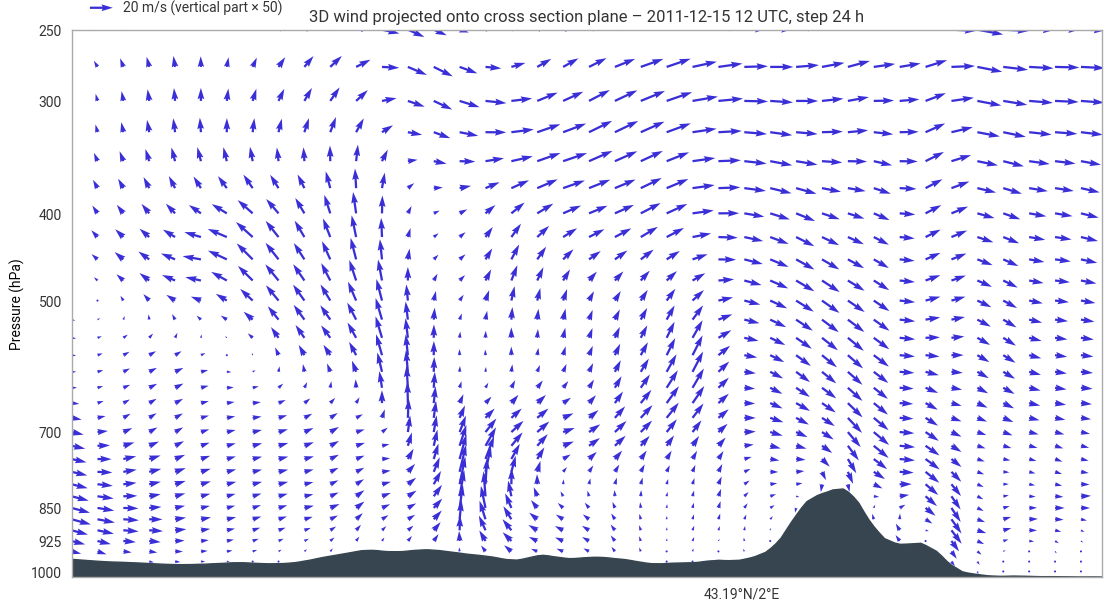

In [14]:
step = 5  # one column of arrows out of 5
cols = slice(None, None, step)
X, Y = np.meshgrid(xs["distance"].values[cols], xs["pressure"].values)  # (pressure, thinned point)
U_arrow = xs["wp"].values[:, cols]  # m/s, along the line (southwards)
V_arrow = 50 * xs["w"].values[:, cols]  # m/s, vertical velocity times 50, up

chart = ekp.Subplot(figsize=(11, 6))
ax = chart.ax
arrows = ax.quiver(X, Y, U_arrow, V_arrow, color="#3a2fd6", angles="uv", scale=900, width=0.0022)
ax.quiverkey(arrows, 0.04, 1.04, 20, "20 m/s (vertical part × 50)", coordinates="axes", labelpos="E")
# orography: charcoal polygon from the surface pressure down to 1015 hPa, drawn on top
chart.fill_between(xs["sp"], 1015, x=xs["distance"], color="#36454f", alpha=1)

# one tick where the line crosses 2°E (lons increase along the line)
tick_distance = np.interp(2.0, lons, distance)
tick_lat = np.interp(2.0, lons, lats)

ax.set_yscale("log")
ax.set_ylim(1015, 250)  # 1015 hPa at the bottom, 250 hPa at the top
pressure_ticks = [1000, 925, 850, 700, 500, 400, 300, 250]
ax.set_yticks(pressure_ticks)
ax.set_yticklabels([str(p) for p in pressure_ticks])
ax.minorticks_off()
ax.set_xlim(distance[0], distance[-1])
ax.set_xticks([tick_distance])
ax.set_xticklabels([f"{tick_lat:.2f}°N/2°E"])
ax.grid(False)  # no grid lines over the arrows, as in Metview
ax.set_ylabel("Pressure (hPa)")
ax.set_title("3D wind projected onto cross section plane – 2011-12-15 12 UTC, step 24 h")

chart.show()